# MLP Baseline for AI-Generated Face Detection

**Owner:** Aditya Mohan Jha (230911428)  
**Task:** Binary classification of real versus AI-generated faces.

This notebook implements a non-convolutional MLP baseline. It converts each
128 × 128 RGB face into 145 global colour-distribution and frequency-domain
features, standardizes them using training data only, and trains an MLP.

- Real = 0; fake = 1.
- Preserve the dataset's supplied train/valid/test partitions.
- Select the checkpoint using validation F1.
- Evaluate the test partition only after the configuration is frozen.
- Report accuracy, fake-class precision/recall/F1, ROC-AUC, and a confusion matrix.

The MLP deliberately does not receive a spatial image tensor. Its role is to
provide a compact baseline against the team's CNN, LSTM, and ViT models.

In [6]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import csv
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler

SEED = 42
IMAGE_SIZE = 128
BATCH_SIZE = 512
MAX_EPOCHS = 30
PATIENCE = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
THRESHOLD = 0.5
FEATURE_WORKERS = 4

RUN_NAME = "full"
LIMIT_PER_CLASS = None
EVALUATE_TEST = True

OUTPUT = Path("/kaggle/working") / f"mlp_{RUN_NAME}"
OUTPUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# Locate the attached dataset without assuming a particular Kaggle mount name.
candidates = sorted(Path("/kaggle/input").glob("**/train/real"))
if not candidates:
    raise FileNotFoundError(
        "Dataset not found. Attach '140k Real and Fake Faces' in Kaggle's "
        "Add Input panel, then rerun this cell."
    )
DATA_ROOT = candidates[0].parent.parent
for split in ("train", "valid", "test"):
    for label in ("real", "fake"):
        assert (DATA_ROOT / split / label).is_dir(), (
            f"Missing directory: {DATA_ROOT / split / label}"
        )

print("Dataset:", DATA_ROOT)
print("Device:", DEVICE)
print("Output:", OUTPUT)
print("Run:", RUN_NAME, "| limit per class:", LIMIT_PER_CLASS,
      "| evaluate test:", EVALUATE_TEST)

Dataset: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
Device: cuda
Output: /kaggle/working/mlp_full
Run: full | limit per class: None | evaluate test: True


## Feature extraction

Each image is resized to 128 × 128 RGB. The resulting **145 features** are:

| Feature group | Count |
|---|---:|
| Per-channel mean, standard deviation, minimum, maximum, and five quantiles | 27 |
| Three 16-bin RGB histograms | 48 |
| 32-bin grayscale histogram | 32 |
| Radial profile of the centered log-FFT magnitude | 32 |
| Low/mid/high spectral energy, high/low ratio, centroid, entropy | 6 |
| **Total** | **145** |

Histograms and frequency summaries describe global image properties; they do
not give the MLP the local spatial structure available to a CNN.

In [7]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_TO_ID = {"real": 0, "fake": 1}

def list_images(split, limit_per_class=None):
    rng = random.Random(SEED)
    items = []
    for class_name, label in CLASS_TO_ID.items():
        folder = DATA_ROOT / split / class_name
        paths = sorted(
            p for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        )
        if not paths:
            raise ValueError(f"No images found in {folder}")
        if limit_per_class is not None:
            paths = rng.sample(paths, min(limit_per_class, len(paths)))
        items.extend((p, label) for p in paths)
        print(f"{split:5s} {class_name:4s}: {len(paths):,}")
    rng.shuffle(items)
    return items

# Geometry is constant for every resized image, so compute it once.
yy, xx = np.indices((IMAGE_SIZE, IMAGE_SIZE))
radius = np.sqrt(
    (yy - (IMAGE_SIZE - 1) / 2) ** 2
    + (xx - (IMAGE_SIZE - 1) / 2) ** 2
)
radius = radius / (radius.max() + 1e-12)
radial_index = np.minimum((radius * 32).astype(np.int32), 31)
radial_count = np.bincount(radial_index.ravel(), minlength=32)
low_mask = radius < 0.25
mid_mask = (radius >= 0.25) & (radius < 0.60)
high_mask = radius >= 0.60

def extract_features(path):
    with Image.open(path) as opened:
        image = ImageOps.exif_transpose(opened).convert("RGB")
        image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)

    rgb = np.asarray(image, dtype=np.float32) / 255.0
    gray = np.asarray(image.convert("L"), dtype=np.float32) / 255.0
    values = []

    for channel in range(3):
        x = rgb[:, :, channel].ravel()
        values.extend([x.mean(), x.std(), x.min(), x.max()])
        values.extend(np.quantile(x, [0.10, 0.25, 0.50, 0.75, 0.90]))
        hist, _ = np.histogram(x, bins=16, range=(0, 1))
        values.extend(hist / x.size)

    gray_hist, _ = np.histogram(gray, bins=32, range=(0, 1))
    values.extend(gray_hist / gray.size)

    spectrum = np.fft.fftshift(np.fft.fft2(gray - gray.mean()))
    log_magnitude = np.log1p(np.abs(spectrum))
    radial_sum = np.bincount(
        radial_index.ravel(), weights=log_magnitude.ravel(), minlength=32
    )
    profile = radial_sum / np.maximum(radial_count, 1)
    profile = (profile - profile.mean()) / (profile.std() + 1e-8)
    values.extend(profile)

    power = np.abs(spectrum) ** 2
    total = power.sum() + 1e-12
    low = power[low_mask].sum() / total
    mid = power[mid_mask].sum() / total
    high = power[high_mask].sum() / total
    centroid = (power * radius).sum() / total
    probabilities = power.ravel() / total
    entropy = -np.sum(
        probabilities * np.log(probabilities + 1e-12)
    ) / np.log(probabilities.size)
    values.extend([low, mid, high, high / (low + 1e-8), centroid, entropy])

    features = np.asarray(values, dtype=np.float32)
    if features.shape != (145,) or not np.isfinite(features).all():
        raise ValueError(f"Invalid features for {path}: {features.shape}")
    return features

def load_split(split, limit_per_class):
    items = list_images(split, limit_per_class)
    cache = OUTPUT / f"{split}_features.npz"

    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            x, y, paths = saved["x"], saved["y"], saved["paths"].tolist()
        expected_paths = [str(p) for p, _ in items]
        if paths != expected_paths:
            raise ValueError(
                f"{cache} is from a different image selection. "
                "Use a new RUN_NAME for a new experiment."
            )
        print(f"Loaded cached {split} features: {x.shape}")
        return x, y, paths

    paths = [p for p, _ in items]
    y = np.asarray([label for _, label in items], dtype=np.int64)
    start = time.time()
    with ThreadPoolExecutor(max_workers=FEATURE_WORKERS) as executor:
        rows = list(tqdm(
            executor.map(extract_features, paths),
            total=len(paths), desc=f"Extracting {split}"
        ))
    x = np.stack(rows)
    path_strings = [str(p) for p in paths]
    np.savez_compressed(
        cache, x=x, y=y, paths=np.asarray(path_strings)
    )
    print(f"{split}: {x.shape}; extraction took {(time.time()-start)/60:.1f} min")
    return x, y, path_strings

X_train_raw, y_train, train_paths = load_split("train", LIMIT_PER_CLASS)
X_valid_raw, y_valid, valid_paths = load_split("valid", LIMIT_PER_CLASS)

assert X_train_raw.shape[1] == X_valid_raw.shape[1] == 145
assert set(np.unique(y_train)) == set(np.unique(y_valid)) == {0, 1}

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_valid = scaler.transform(X_valid_raw).astype(np.float32)
np.savez(OUTPUT / "standard_scaler.npz",
         mean=scaler.mean_, scale=scaler.scale_)

train real: 50,000
train fake: 50,000


Extracting train:   0%|          | 0/100000 [00:00<?, ?it/s]

train: (100000, 145); extraction took 21.7 min
valid real: 10,000
valid fake: 10,000


Extracting valid:   0%|          | 0/20000 [00:00<?, ?it/s]

valid: (20000, 145); extraction took 3.1 min


## MLP and validation-based training

Architecture: **145 → 256 → 128 → 32 → 1 logit**. The first two hidden
layers use batch normalization, ReLU, and dropout. Training uses
`BCEWithLogitsLoss` and AdamW. The highest **validation F1** determines
the saved checkpoint; early stopping occurs after five non-improving epochs.
A fixed probability threshold of 0.5 is used throughout.

In [8]:
class MLPBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(145, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(0.35),
            nn.Linear(256, 128), nn.BatchNorm1d(128),
            nn.ReLU(), nn.Dropout(0.30),
            nn.Linear(128, 32), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.layers(x).squeeze(1)

def make_loader(x, y, shuffle):
    ds = TensorDataset(
        torch.from_numpy(x),
        torch.from_numpy(y.astype(np.float32))
    )
    return DataLoader(
        ds, batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=0, pin_memory=(DEVICE.type == "cuda")
    )

def calculate_metrics(y, prob):
    pred = (prob >= THRESHOLD).astype(int)
    result = {
        "accuracy": float(accuracy_score(y, pred)),
        "precision_fake": float(precision_score(y, pred, zero_division=0)),
        "recall_fake": float(recall_score(y, pred, zero_division=0)),
        "f1_fake": float(f1_score(y, pred, zero_division=0)),
    }
    result["roc_auc"] = float(roc_auc_score(y, prob))
    return result

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probabilities, labels = [], []
    loss_sum = 0.0
    criterion = nn.BCEWithLogitsLoss(reduction="sum")
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        loss_sum += criterion(logits, y).item()
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
        labels.append(y.cpu().numpy())
    prob = np.concatenate(probabilities)
    true = np.concatenate(labels).astype(int)
    return true, prob, loss_sum / len(true)

train_loader = make_loader(X_train, y_train, shuffle=True)
valid_loader = make_loader(X_valid, y_valid, shuffle=False)

model = MLPBaseline().to(DEVICE)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
criterion = nn.BCEWithLogitsLoss()
history = []
best_f1 = -1.0
best_epoch = None
stale = 0
start = time.time()

config = {
    "owner": "Aditya Mohan Jha",
    "dataset_root": str(DATA_ROOT),
    "run_name": RUN_NAME,
    "limit_per_class_per_split": LIMIT_PER_CLASS,
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "feature_dim": 145,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "threshold": THRESHOLD,
    "checkpoint_selection": "highest validation F1",
    "train_count": len(y_train),
    "valid_count": len(y_valid),
    "torch_version": torch.__version__,
}
(OUTPUT / "config.json").write_text(json.dumps(config, indent=2))

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * len(y)

    val_y, val_prob, val_loss = evaluate(model, valid_loader)
    metrics = calculate_metrics(val_y, val_prob)
    row = {
        "epoch": epoch,
        "train_loss": train_loss_sum / len(y_train),
        "valid_loss": val_loss,
        **{f"valid_{key}": value for key, value in metrics.items()}
    }
    history.append(row)
    print(
        f"Epoch {epoch:02d} | train loss {row['train_loss']:.4f} | "
        f"valid loss {val_loss:.4f} | valid F1 {metrics['f1_fake']:.4f} | "
        f"valid AUC {metrics['roc_auc']:.4f}"
    )

    if metrics["f1_fake"] > best_f1 + 1e-4:
        best_f1 = metrics["f1_fake"]
        best_epoch = epoch
        stale = 0
        torch.save(model.state_dict(), OUTPUT / "best_mlp.pt")
    else:
        stale += 1
        if stale >= PATIENCE:
            print("Early stopping.")
            break

with (OUTPUT / "training_history.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=history[0].keys())
    writer.writeheader()
    writer.writerows(history)

model.load_state_dict(
    torch.load(OUTPUT / "best_mlp.pt", map_location=DEVICE, weights_only=True)
)
val_y, val_prob, val_loss = evaluate(model, valid_loader)
validation_metrics = {
    "best_epoch": best_epoch,
    "valid_loss": val_loss,
    **calculate_metrics(val_y, val_prob)
}
(OUTPUT / "validation_metrics.json").write_text(
    json.dumps(validation_metrics, indent=2)
)

print("\nBest checkpoint:", best_epoch)
print(json.dumps(validation_metrics, indent=2))
print(f"Training time: {(time.time()-start)/60:.1f} min")

Epoch 01 | train loss 0.6330 | valid loss 0.5876 | valid F1 0.6798 | valid AUC 0.7590
Epoch 02 | train loss 0.5852 | valid loss 0.5556 | valid F1 0.7225 | valid AUC 0.7904
Epoch 03 | train loss 0.5654 | valid loss 0.5423 | valid F1 0.7280 | valid AUC 0.8013
Epoch 04 | train loss 0.5546 | valid loss 0.5366 | valid F1 0.7304 | valid AUC 0.8057
Epoch 05 | train loss 0.5449 | valid loss 0.5278 | valid F1 0.7421 | valid AUC 0.8131
Epoch 06 | train loss 0.5363 | valid loss 0.5240 | valid F1 0.7471 | valid AUC 0.8179
Epoch 07 | train loss 0.5314 | valid loss 0.5202 | valid F1 0.7448 | valid AUC 0.8199
Epoch 08 | train loss 0.5262 | valid loss 0.5157 | valid F1 0.7495 | valid AUC 0.8233
Epoch 09 | train loss 0.5217 | valid loss 0.5114 | valid F1 0.7544 | valid AUC 0.8265
Epoch 10 | train loss 0.5150 | valid loss 0.5095 | valid F1 0.7478 | valid AUC 0.8283
Epoch 11 | train loss 0.5118 | valid loss 0.5046 | valid F1 0.7583 | valid AUC 0.8325
Epoch 12 | train loss 0.5065 | valid loss 0.5021 | val

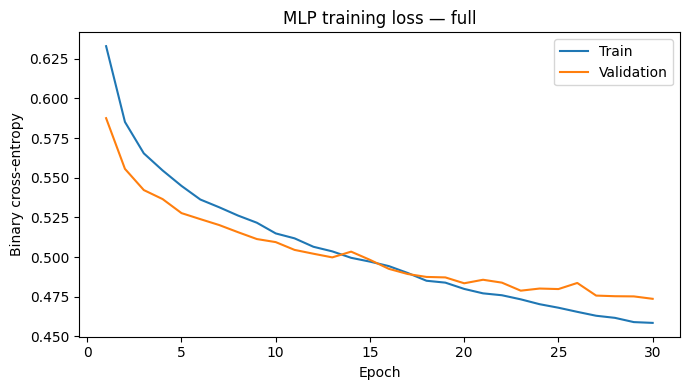

In [9]:
epochs = [row["epoch"] for row in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [row["train_loss"] for row in history], label="Train")
plt.plot(epochs, [row["valid_loss"] for row in history], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title(f"MLP training loss — {RUN_NAME}")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "training_curve.png", dpi=180)
plt.show()

In [16]:
EVALUATE_TEST = True

## Final test evaluation

Run the next cell only when the model configuration is frozen. For the full
experiment, first change the configuration to `RUN_NAME = "full"`,
`LIMIT_PER_CLASS = None`, and `EVALUATE_TEST = True`; then rerun the notebook
from the beginning. The preliminary run's validation metrics are useful for
checking the pipeline but are **not** full-dataset test results.

If time permits only a fixed subset experiment, label it explicitly as a
subset in the paper. Do not describe subset results as full-dataset results.

test  real: 10,000
test  fake: 10,000
Loaded cached test features: (20000, 145)
{
  "run_name": "full",
  "test_count": 20000,
  "best_epoch": 29,
  "threshold": 0.5,
  "test_loss": 0.46992228779792783,
  "accuracy": 0.7757,
  "precision_fake": 0.7621220764403879,
  "recall_fake": 0.8016,
  "f1_fake": 0.781362705916756,
  "roc_auc": 0.8572348949999999
}


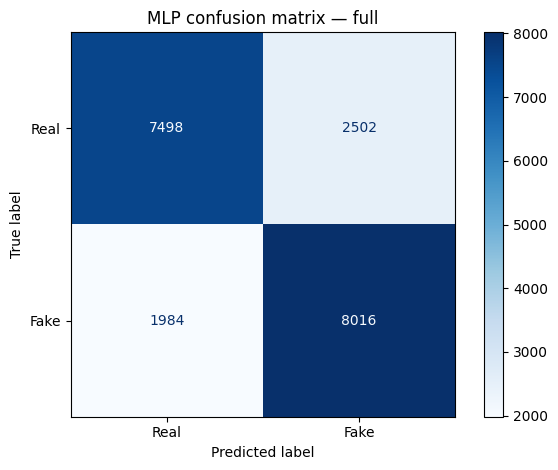

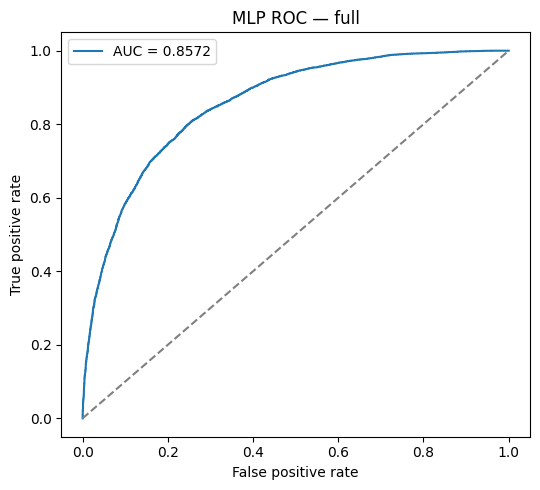

False positives: 2502
False negatives: 1984
Example false positives: ['/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/real/35614.jpg', '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/real/34437.jpg', '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/real/07851.jpg', '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/real/50777.jpg', '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/real/05094.jpg']
Example false negatives: ['/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/fake/EYFF1GX22R.jpg', '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/fake/2DOTOSSMDW.jpg', '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test/fake/ZWEJOHNX2Z.jpg', '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/r

In [17]:
if not EVALUATE_TEST:
    print("Test evaluation skipped. Set EVALUATE_TEST=True only for the "
          "frozen final experiment, then rerun from the beginning.")
else:
    X_test_raw, y_test, test_paths = load_split("test", LIMIT_PER_CLASS)
    X_test = scaler.transform(X_test_raw).astype(np.float32)
    test_loader = make_loader(X_test, y_test, shuffle=False)

    test_y, test_prob, test_loss = evaluate(model, test_loader)
    test_pred = (test_prob >= THRESHOLD).astype(int)
    test_metrics = {
        "run_name": RUN_NAME,
        "test_count": len(test_y),
        "best_epoch": best_epoch,
        "threshold": THRESHOLD,
        "test_loss": test_loss,
        **calculate_metrics(test_y, test_prob)
    }
    (OUTPUT / "test_metrics.json").write_text(
        json.dumps(test_metrics, indent=2)
    )
    print(json.dumps(test_metrics, indent=2))

    with (OUTPUT / "test_predictions.csv").open(
        "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.writer(f)
        writer.writerow([
            "path", "true_label", "probability_fake", "predicted_label"
        ])
        for path, true, prob, pred in zip(
            test_paths, test_y, test_prob, test_pred
        ):
            writer.writerow([path, int(true), float(prob), int(pred)])

    cm = confusion_matrix(test_y, test_pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        cm, display_labels=["Real", "Fake"]
    ).plot(cmap="Blues", values_format="d")
    plt.title(f"MLP confusion matrix — {RUN_NAME}")
    plt.tight_layout()
    plt.savefig(OUTPUT / "confusion_matrix.png", dpi=180)
    plt.show()

    fpr, tpr, _ = roc_curve(test_y, test_prob)
    plt.figure(figsize=(5.5, 5))
    plt.plot(fpr, tpr, label=f"AUC = {test_metrics['roc_auc']:.4f}")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"MLP ROC — {RUN_NAME}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT / "roc_curve.png", dpi=180)
    plt.show()

    false_positives = np.where((test_y == 0) & (test_pred == 1))[0]
    false_negatives = np.where((test_y == 1) & (test_pred == 0))[0]
    print("False positives:", len(false_positives))
    print("False negatives:", len(false_negatives))
    print("Example false positives:",
          [test_paths[i] for i in false_positives[:5]])
    print("Example false negatives:",
          [test_paths[i] for i in false_negatives[:5]])

In [19]:
from pathlib import Path

print("Current OUTPUT:", OUTPUT.resolve())
print("Training examples in memory:", len(y_train))
print("Best epoch in memory:", best_epoch)
print("Test metric files:")
for p in Path("/kaggle/working").rglob("test_metrics.json"):
    print(p, "->", p.read_text()[:500])

Current OUTPUT: /kaggle/working/mlp_full
Training examples in memory: 100000
Best epoch in memory: 29
Test metric files:
/kaggle/working/mlp_full/test_metrics.json -> {
  "run_name": "full",
  "test_count": 20000,
  "best_epoch": 29,
  "threshold": 0.5,
  "test_loss": 0.46992228779792783,
  "accuracy": 0.7757,
  "precision_fake": 0.7621220764403879,
  "recall_fake": 0.8016,
  "f1_fake": 0.781362705916756,
  "roc_auc": 0.8572348949999999
}


In [20]:
from IPython.display import display, FileLink
from pathlib import Path

folder = Path("/kaggle/working/mlp_full")
for name in [
    "test_metrics.json", "config.json", "training_history.csv",
    "confusion_matrix.png", "roc_curve.png", "training_curve.png",
    "test_predictions.csv"
]:
    path = folder / name
    if path.exists():
        display(FileLink(str(path)))

/kaggle/working/mlp_full/test_metrics.json

/kaggle/working/mlp_full/config.json

/kaggle/working/mlp_full/training_history.csv

/kaggle/working/mlp_full/confusion_matrix.png

/kaggle/working/mlp_full/roc_curve.png

/kaggle/working/mlp_full/training_curve.png

/kaggle/working/mlp_full/test_predictions.csv

In [21]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

source = Path("/kaggle/working/mlp_full")
archive = Path("/kaggle/working/aditya_mlp_full_results.zip")

names = [
    "test_metrics.json", "config.json", "validation_metrics.json",
    "training_history.csv", "confusion_matrix.png", "roc_curve.png",
    "training_curve.png", "test_predictions.csv",
]

with ZipFile(archive, "w", ZIP_DEFLATED) as z:
    for name in names:
        path = source / name
        if path.exists():
            z.write(path, arcname=name)
        else:
            print("Not found:", name)

print("Created:", archive, "| size:", archive.stat().st_size, "bytes")

Created: /kaggle/working/aditya_mlp_full_results.zip | size: 524934 bytes
